<a href="https://colab.research.google.com/github/samnocera05-ui/mis433/blob/main/churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Competition - Customer Churn Prediction

MIS 433 - Fall 2026

Customer churn is the loss of clients or customers. In this notebook, I conduct a churn analysis on a data set of a telecommunication company and build decision tree models to predict customer churn.

Outline:
1. Read the data files
2. Describe/summarize the data sets
3. Data integration
4. Exploratory data analysis
5. Models building
6. Making predictions for submission on Kaggle

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
# Colab only: mount Google Drive and set the data folder and the output folder for submissions
from google.colab import drive

drive.mount('/content/drive')

data_dir = '/content/drive/My Drive/Colab Notebooks/Assignments/MIS 433 - Churn Competition/data/'
output_dir = '/content/drive/My Drive/Colab Notebooks/Assignments/MIS 433 - Churn Competition/output/'
os.makedirs(output_dir, exist_ok=True)
print(f'Submission files will be saved to: {output_dir}')

Mounted at /content/drive
Submission files will be saved to: /content/drive/My Drive/Colab Notebooks/Assignments/MIS 433 - Churn Competition/output/


## 1. Read the Data Files

The competition provides six files:
- `churn_train.csv` - the training set (CustomerNo and Churn)
- `churn_test.csv` - the test set (CustomerNo only)
- `accounts.csv` - account information of all customers
- `demographics.csv` - demographics of all customers
- `services.csv` - services opted for by all customers
- `sample_submission.csv` - a sample submission file in the correct format

In [3]:
# Load the training set
df_train = pd.read_csv(f'{data_dir}churn_train.csv')
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   CustomerNo  4238 non-null   int64
 1   Churn       4238 non-null   int64
dtypes: int64(2)
memory usage: 66.3 KB


In [4]:
# Load the test set
df_test = pd.read_csv(f'{data_dir}churn_test.csv')
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1060 entries, 0 to 1059
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   CustomerNo  1060 non-null   int64
dtypes: int64(1)
memory usage: 8.4 KB


In [5]:
# Load the three tables that describe the customers
df_accounts = pd.read_csv(f'{data_dir}accounts.csv')
df_demographics = pd.read_csv(f'{data_dir}demographics.csv')
df_services = pd.read_csv(f'{data_dir}services.csv')

## 2. Describe/Summarize the Data Sets

In [6]:
# rows and columns of each data set
print(df_train.shape)
print(df_test.shape)
print(df_accounts.shape)
print(df_demographics.shape)
print(df_services.shape)

(4238, 2)
(1060, 1)
(5298, 8)
(5298, 8)
(47682, 3)


### Training set

In [7]:
df_train.head()

,CustomerNo,Churn
0,1201,0
1,1202,0
2,1205,1
3,1206,0
4,1207,0


In [8]:
# 'Churn' is the target
s = df_train['Churn'].value_counts()
print(s)
print(f'the churn rate is {s[1]/s.sum():.1%}')

Churn
0    3189
1    1049
Name: count, dtype: int64
the churn rate is 24.8%


About one out of four customers in the training set churned. A naive model that predicts Churn = 0 for all would be right about 75% of the time on the training set.

### Accounts

In [9]:
df_accounts.head()

,CustomerNo,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod
0,1201,478.50,5-1-2012,5920.00,10-Jan-11,No,One year,Electronic check
1,1202,103.25,5-1-2012,103.25,6-Dec-11,No,Month-to-month,Electronic check
2,1203,399.75,5-1-2012,5217.00,10-Jan-11,Yes,Month-to-month,Bank transfer (automatic)
3,1204,324.75,5-1-2012,22757.50,6-Apr-06,No,One year,Bank transfer (automatic)
4,1205,372.50,5-1-2012,372.50,6-Dec-11,Yes,Month-to-month,Electronic check


In [10]:
df_accounts.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5298 entries, 0 to 5297
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerNo         5298 non-null   int64  
 1   BaseCharges        5298 non-null   float64
 2   DOC                5298 non-null   object 
 3   TotalCharges       5288 non-null   float64
 4   DOE                5298 non-null   object 
 5   ElectronicBilling  5298 non-null   object 
 6   ContractType       5293 non-null   object 
 7   PaymentMethod      5298 non-null   object 
dtypes: float64(2), int64(1), object(5)
memory usage: 331.3+ KB


In [11]:
df_accounts.describe(include='all')

,CustomerNo,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod
count,5298.000000,5298.000000,5298,5288.000000,5298,5298,5293,5298
unique,NaN,NaN,1,NaN,73,2,3,4
top,NaN,NaN,5-1-2012,NaN,6-Dec-11,Yes,Month-to-month,Electronic check
freq,NaN,NaN,5298,NaN,423,3120,2779,1586
mean,3849.500000,325.467205,NaN,11928.354056,NaN,NaN,NaN,NaN
std,1529.545194,151.352954,NaN,11486.453199,NaN,NaN,NaN,NaN
min,1201.000000,91.250000,NaN,94.250000,NaN,NaN,NaN,NaN
25%,2525.250000,178.250000,NaN,2314.937500,NaN,NaN,NaN,NaN
50%,3849.500000,352.500000,NaN,7377.500000,NaN,NaN,NaN,NaN
75%,5173.750000,451.250000,NaN,19992.812500,NaN,NaN,NaN,NaN


In [12]:
# total null values
df_accounts.isnull().sum()

,0
CustomerNo,0
BaseCharges,0
DOC,0
TotalCharges,10
DOE,0
ElectronicBilling,0
ContractType,5
PaymentMethod,0


- `DOC` has only one value (5-1-2012) for every customer.
- `DOE` is a date stored as text.
- `TotalCharges` has 10 missing values and `ContractType` has 5.

### Demographics

In [13]:
df_demographics.head()

,CustomerNo,Country,State,Retired,HasPartner,HasDependents,Education,Gender
0,1201,India,Maharashtra,0,2,2,Masters,Male
1,1202,India,Maharashtra,0,2,2,ProfessionalQalification,Male
2,1203,India,Maharashtra,0,2,2,ProfessionalQalification,Male
3,1204,India,Maharashtra,0,2,1,ProfessionalQalification,Male
4,1205,India,Maharashtra,0,2,2,ProfessionalQalification,Female


In [14]:
df_demographics.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5298 entries, 0 to 5297
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   CustomerNo     5298 non-null   int64 
 1   Country        5298 non-null   object
 2   State          5298 non-null   object
 3   Retired        5298 non-null   int64 
 4   HasPartner     5298 non-null   int64 
 5   HasDependents  5298 non-null   int64 
 6   Education      5288 non-null   object
 7   Gender         5294 non-null   object
dtypes: int64(4), object(4)
memory usage: 331.3+ KB


In [15]:
df_demographics.describe(include='all')

,CustomerNo,Country,State,Retired,HasPartner,HasDependents,Education,Gender
count,5298.000000,5298,5298,5298.000000,5298.000000,5298.000000,5288,5294
unique,NaN,2,2,NaN,NaN,NaN,5,2
top,NaN,India,Maharashtra,NaN,NaN,NaN,Highschool or below,Male
freq,NaN,5293,5290,NaN,NaN,NaN,1426,2656
mean,3849.500000,NaN,NaN,0.158362,1.502454,1.690827,NaN,NaN
std,1529.545194,NaN,NaN,0.365114,0.500041,0.462196,NaN,NaN
min,1201.000000,NaN,NaN,0.000000,1.000000,1.000000,NaN,NaN
25%,2525.250000,NaN,NaN,0.000000,1.000000,1.000000,NaN,NaN
50%,3849.500000,NaN,NaN,0.000000,2.000000,2.000000,NaN,NaN
75%,5173.750000,NaN,NaN,0.000000,2.000000,2.000000,NaN,NaN


In [16]:
df_demographics.isnull().sum()

,0
CustomerNo,0
Country,0
State,0
Retired,0
HasPartner,0
HasDependents,0
Education,10
Gender,4


In [17]:
df_demographics['Country'].value_counts()

,count
Country,
India,5293
?,5


In [18]:
df_demographics['State'].value_counts()

,count
State,
Maharashtra,5290
?,8


In [19]:
df_demographics['Education'].value_counts()

,count
Education,
Highschool or below,1426
Graduation,1370
Masters,1265
ProfessionalQalification,1186
Other,41


- `Country` and `State` are almost constant (India / Maharashtra, with a few '?'), so they are not useful for predicting.
- `HasPartner` and `HasDependents` are coded as 1 and 2.
- `Education` has 10 missing values and `Gender` has 4.

### Services

In [20]:
df_services.head(10)

,CustomerNo,TypeOfService,SeviceDetails
0,1201,DeviceProtection,Yes
1,1201,HasPhoneService,1
2,1201,InternetServiceCategory,Fiber optic
3,1201,MultipleLines,No
4,1201,OnlineBackup,No
5,1201,OnlineSecurity,No
6,1201,StreamingMovies,Yes
7,1201,StreamingTelevision,Yes
8,1201,TechnicalSupport,No
9,1202,DeviceProtection,No internet service


In [21]:
df_services.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47682 entries, 0 to 47681
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   CustomerNo     47682 non-null  int64 
 1   TypeOfService  47682 non-null  object
 2   SeviceDetails  47682 non-null  object
dtypes: int64(1), object(2)
memory usage: 1.1+ MB


In [22]:
# each customer has 9 rows, one for each type of service
df_services.groupby('TypeOfService')['SeviceDetails'].value_counts()

TypeOfService            SeviceDetails      
DeviceProtection         No                     2253
                         Yes                    1889
                         No internet service    1156
HasPhoneService          1                      4792
                         0                       506
InternetServiceCategory  Fiber optic            2313
                         DSL                    1829
                         No                     1156
MultipleLines            No                     2491
                         Yes                    2301
                         No phone service        506
OnlineBackup             No                     2270
                         Yes                    1872
                         No internet service    1156
OnlineSecurity           No                     2569
                         Yes                    1573
                         No internet service    1156
StreamingMovies          Yes                    2075
                         No                     2067
                         No internet service    1156
StreamingTelevision      Yes                    2075
                         No                     2067
                         No internet service    1156
TechnicalSupport         No                     2537
                         Yes                    1605
                         No internet service    1156
Name: count, dtype: int64

The services table is not tidy: each customer has 9 rows, and the variable names are stored in the `TypeOfService` column. It needs to be pivoted to a wide table (one row per customer) before it can be merged with the other tables.

## 3. Data Integration

### Tidy the services table

In [23]:
# pivot the services table from long to wide: one row per customer, one column per type of service
df_services_wide = df_services.pivot(index='CustomerNo', columns='TypeOfService', values='SeviceDetails').reset_index()
df_services_wide.head()

TypeOfService,CustomerNo,DeviceProtection,HasPhoneService,InternetServiceCategory,MultipleLines,OnlineBackup,OnlineSecurity,StreamingMovies,StreamingTelevision,TechnicalSupport
0,1201,Yes,1,Fiber optic,No,No,No,Yes,Yes,No
1,1202,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service
2,1203,No,1,Fiber optic,No,No,No,Yes,No,No
3,1204,No,1,DSL,Yes,Yes,Yes,No,No,Yes
4,1205,No,1,Fiber optic,Yes,No,No,No,No,No


In [24]:
df_services_wide.shape

(5298, 10)

### Merge the tables

In [25]:
# combine accounts, demographics, and services into one customer table using CustomerNo as the key
df_customers = pd.merge(df_accounts, df_demographics, how='left', on='CustomerNo')
df_customers = pd.merge(df_customers, df_services_wide, how='left', on='CustomerNo')
df_customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5298 entries, 0 to 5297
Data columns (total 24 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   CustomerNo               5298 non-null   int64  
 1   BaseCharges              5298 non-null   float64
 2   DOC                      5298 non-null   object 
 3   TotalCharges             5288 non-null   float64
 4   DOE                      5298 non-null   object 
 5   ElectronicBilling        5298 non-null   object 
 6   ContractType             5293 non-null   object 
 7   PaymentMethod            5298 non-null   object 
 8   Country                  5298 non-null   object 
 9   State                    5298 non-null   object 
 10  Retired                  5298 non-null   int64  
 11  HasPartner               5298 non-null   int64  
 12  HasDependents            5298 non-null   int64  
 13  Education                5288 non-null   object 
 14  Gender                  

In [26]:
# add the customer information to the training set and the test set
df = pd.merge(df_train, df_customers, how='left', on='CustomerNo')
df_test = pd.merge(df_test, df_customers, how='left', on='CustomerNo')
print(df.shape)
print(df_test.shape)

(4238, 25)
(1060, 24)


In [27]:
df.head()

,CustomerNo,Churn,BaseCharges,DOC,TotalCharges,DOE,ElectronicBilling,ContractType,PaymentMethod,Country,...,Gender,DeviceProtection,HasPhoneService,InternetServiceCategory,MultipleLines,OnlineBackup,OnlineSecurity,StreamingMovies,StreamingTelevision,TechnicalSupport
0,1201,0,478.50,5-1-2012,5920.00,10-Jan-11,No,One year,Electronic check,India,...,Male,Yes,1,Fiber optic,No,No,No,Yes,Yes,No
1,1202,0,103.25,5-1-2012,103.25,6-Dec-11,No,Month-to-month,Electronic check,India,...,Male,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service
2,1205,1,372.50,5-1-2012,372.50,6-Dec-11,Yes,Month-to-month,Electronic check,India,...,Female,No,1,Fiber optic,Yes,No,No,No,No,No
3,1206,0,99.50,5-1-2012,6775.50,7-Mar-06,Yes,Two year,Credit card (automatic),India,...,Male,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service
4,1207,0,91.25,5-1-2012,2673.50,17-Sep-09,No,One year,Credit card (automatic),India,...,Male,No internet service,1,No,No,No internet service,No internet service,No internet service,No internet service,No internet service


In [28]:
# save CustomerNo column of the test set for submission
df_test_id = df_test['CustomerNo']

In [29]:
# CustomerNo is not very useful for predicting
# Country and State are almost constant
# DOC has only one value and DOE is a date stored as text
# let's drop these columns
df.drop(['CustomerNo', 'Country', 'State', 'DOC', 'DOE'], axis=1, inplace=True)
df_test.drop(['CustomerNo', 'Country', 'State', 'DOC', 'DOE'], axis=1, inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Churn                    4238 non-null   int64  
 1   BaseCharges              4238 non-null   float64
 2   TotalCharges             4230 non-null   float64
 3   ElectronicBilling        4238 non-null   object 
 4   ContractType             4235 non-null   object 
 5   PaymentMethod            4238 non-null   object 
 6   Retired                  4238 non-null   int64  
 7   HasPartner               4238 non-null   int64  
 8   HasDependents            4238 non-null   int64  
 9   Education                4229 non-null   object 
 10  Gender                   4236 non-null   object 
 11  DeviceProtection         4238 non-null   object 
 12  HasPhoneService          4238 non-null   object 
 13  InternetServiceCategory  4238 non-null   object 
 14  MultipleLines           

## 4. Exploratory Data Analysis

In [30]:
df.describe()

,Churn,BaseCharges,TotalCharges,Retired,HasPartner,HasDependents
count,4238.000000,4238.000000,4230.000000,4238.000000,4238.000000,4238.000000
mean,0.247522,325.912872,11927.019622,0.156678,1.503067,1.693016
std,0.431624,151.166462,11514.252452,0.363540,0.500050,0.461297
min,0.000000,91.250000,94.250000,0.000000,1.000000,1.000000
25%,0.000000,183.500000,2286.750000,0.000000,1.000000,1.000000
50%,0.000000,352.375000,7457.625000,0.000000,2.000000,2.000000
75%,0.000000,452.000000,19966.125000,0.000000,2.000000,2.000000
max,1.000000,593.750000,43362.250000,1.000000,2.000000,2.000000


In [31]:
# total null values in the training set
df.isnull().sum()

,0
Churn,0
BaseCharges,0
TotalCharges,8
ElectronicBilling,0
ContractType,3
PaymentMethod,0
Retired,0
HasPartner,0
HasDependents,0
Education,9


In [32]:
# total null values in the test set
df_test.isnull().sum()

,0
BaseCharges,0
TotalCharges,2
ElectronicBilling,0
ContractType,2
PaymentMethod,0
Retired,0
HasPartner,0
HasDependents,0
Education,1
Gender,2


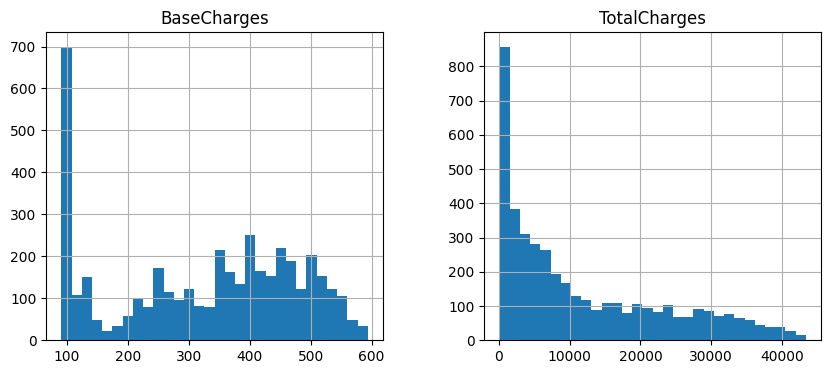

In [33]:
# histograms for the two charges variables
df[['BaseCharges', 'TotalCharges']].hist(figsize=(10,4), bins=30)
plt.show()

- `BaseCharges` has a big group of customers with low charges and the rest spread between about 200 and 550.
- `TotalCharges` is skewed to the right.

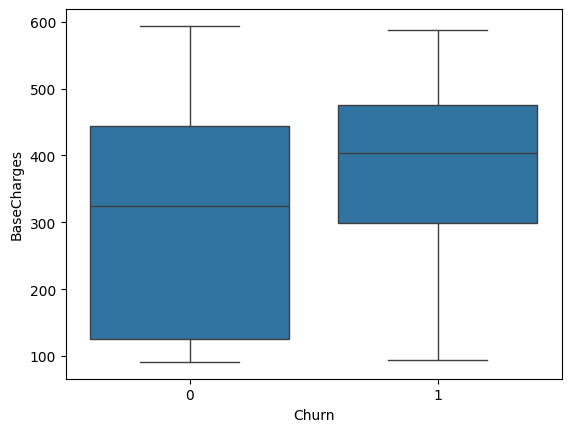

In [34]:
sns.boxplot(data=df, x='Churn', y='BaseCharges')
plt.show()

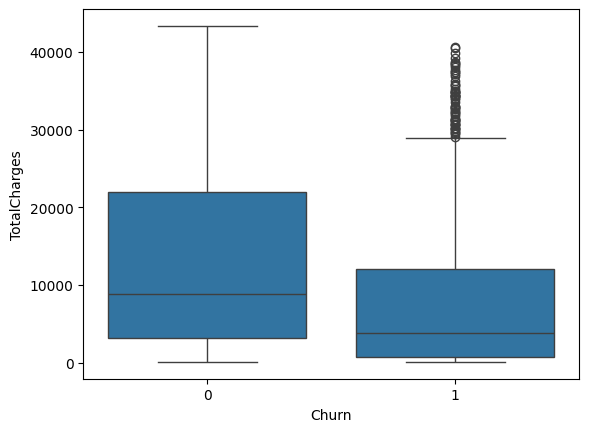

In [35]:
sns.boxplot(data=df, x='Churn', y='TotalCharges')
plt.show()

Customers who churned have higher base charges but lower total charges. Lower total charges suggest they did not stay with the company for long.

In [36]:
# churn rate by contract type
df.groupby('ContractType')['Churn'].value_counts(normalize=True)

ContractType    Churn
Month-to-month  0        0.589709
                1        0.410291
One year        0        0.890098
                1        0.109902
Two year        0        0.972248
                1        0.027752
Name: proportion, dtype: float64

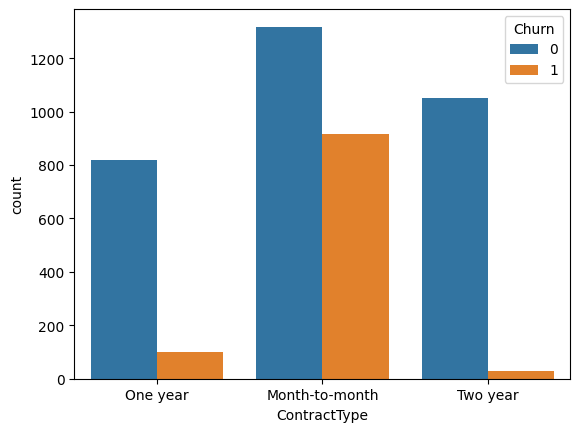

In [37]:
sns.countplot(data=df, x='ContractType', hue='Churn')
plt.show()

In [38]:
# churn rate by payment method
df.groupby('PaymentMethod')['Churn'].value_counts(normalize=True)

PaymentMethod              Churn
Bank transfer (automatic)  0        0.830752
                           1        0.169248
Credit card (automatic)    0        0.848091
                           1        0.151909
Electronic check           0        0.558268
                           1        0.441732
Mailed check               0        0.822329
                           1        0.177671
Name: proportion, dtype: float64

In [39]:
# churn rate by internet service
df.groupby('InternetServiceCategory')['Churn'].value_counts(normalize=True)

InternetServiceCategory  Churn
DSL                      0        0.828938
                         1        0.171062
Fiber optic              0        0.600648
                         1        0.399352
No                       0        0.938190
                         1        0.061810
Name: proportion, dtype: float64

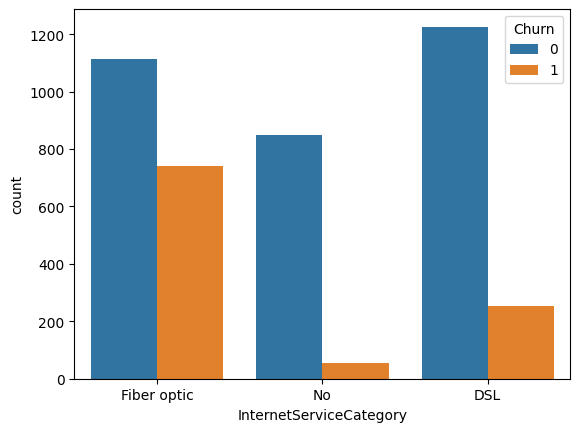

In [40]:
sns.countplot(data=df, x='InternetServiceCategory', hue='Churn')
plt.show()

In [41]:
# churn rate by online security
df.groupby('OnlineSecurity')['Churn'].value_counts(normalize=True)

OnlineSecurity       Churn
No                   0        0.606280
                     1        0.393720
No internet service  0        0.938190
                     1        0.061810
Yes                  0        0.858954
                     1        0.141046
Name: proportion, dtype: float64

In [42]:
# churn rate by gender
df.groupby('Gender')['Churn'].value_counts(normalize=True)

Gender  Churn
Female  0        0.743468
        1        0.256532
Male    0        0.761614
        1        0.238386
Name: proportion, dtype: float64

In [43]:
# churn rate by retired
df.groupby('Retired')['Churn'].value_counts(normalize=True)

Retired  Churn
0        0        0.780078
         1        0.219922
1        0        0.603916
         1        0.396084
Name: proportion, dtype: float64

- **ContractType**: month-to-month customers churn far more (41%) than customers on one-year (11%) or two-year (3%) contracts.
- **PaymentMethod**: customers paying by electronic check churn the most (44%).
- **InternetServiceCategory**: fiber optic customers churn more than DSL customers; customers with no internet service rarely churn.
- **OnlineSecurity**: customers without online security churn more.
- **Gender** makes almost no difference. Retired customers churn more.

## 5. Models Building

I build three decision tree models:
1. Decision tree using the numerical variables only
2. Decision tree using numerical and categorical variables, with ordinal encoding
3. Decision tree using numerical and categorical variables, with one-hot encoding

### Model 1: Decision tree using the numerical variables only

For the first model, I follow the step-by-step process: handle missing values, scale, and then train the tree.

In [44]:
# set the target
y = df['Churn']
X = df.drop('Churn', axis=1)
print(X.shape)
print(y.shape)

(4238, 19)
(4238,)


In [45]:
# select only numerical attributes
# NOTE: Retired, HasPartner, and HasDependents only have two values each.
# I treat them as numerical attributes here to keep it simple.
df_num = X.select_dtypes(include=['int64','float64'])
df_num.head()

,BaseCharges,TotalCharges,Retired,HasPartner,HasDependents
0,478.50,5920.00,0,2,2
1,103.25,103.25,0,2,2
2,372.50,372.50,0,2,2
3,99.50,6775.50,0,2,2
4,91.25,2673.50,0,2,2


In [46]:
df_num.isnull().sum()

,0
BaseCharges,0
TotalCharges,8
Retired,0
HasPartner,0
HasDependents,0


In [47]:
# fill the missing values in TotalCharges with median using Scikit-Learn SimpleImputer
from sklearn.impute import SimpleImputer
median_imputer = SimpleImputer(strategy='median')

df_num_fill_median = median_imputer.fit_transform(df_num)
median_imputer.statistics_

array([3.523750e+02, 7.457625e+03, 0.000000e+00, 2.000000e+00,
       2.000000e+00])

In [48]:
# change a numpy array to a DataFrame
df_num_fill_median = pd.DataFrame(df_num_fill_median, columns=df_num.columns)
df_num_fill_median.isnull().sum()  # no missing values

,0
BaseCharges,0
TotalCharges,0
Retired,0
HasPartner,0
HasDependents,0


In [49]:
df_num_fill_median.describe()

,BaseCharges,TotalCharges,Retired,HasPartner,HasDependents
count,4238.000000,4238.000000,4238.000000,4238.000000,4238.000000
mean,325.912872,11918.582822,0.156678,1.503067,1.693016
std,151.166462,11505.013268,0.363540,0.500050,0.461297
min,91.250000,94.250000,0.000000,1.000000,1.000000
25%,183.500000,2298.750000,0.000000,1.000000,1.000000
50%,352.375000,7457.625000,0.000000,2.000000,2.000000
75%,452.000000,19938.562500,0.000000,2.000000,2.000000
max,593.750000,43362.250000,1.000000,2.000000,2.000000


These numerical variables have very different distributions (e.g., TotalCharges goes up to 43,424 while Retired is 0 or 1), so I scale them to lie between zero and one.

In [50]:
from sklearn.preprocessing import MinMaxScaler

min_max_scaler = MinMaxScaler()
df_num_fill_median_scaled = min_max_scaler.fit_transform(df_num_fill_median)

# change df_num_fill_median_scaled into dataframe
df_num_processed = pd.DataFrame(df_num_fill_median_scaled, columns=df_num_fill_median.columns)
df_num_processed.describe()

,BaseCharges,TotalCharges,Retired,HasPartner,HasDependents
count,4238.000000,4238.000000,4238.000000,4238.000000,4238.000000
mean,0.466991,0.273281,0.156678,0.503067,0.693016
std,0.300829,0.265901,0.363540,0.500050,0.461297
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.183582,0.050950,0.000000,0.000000,0.000000
50%,0.519652,0.170181,0.000000,1.000000,1.000000
75%,0.717910,0.458637,0.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000


In [51]:
# train a DT model using the numerical variables
from sklearn.tree import DecisionTreeClassifier
tree_clf1 = DecisionTreeClassifier(criterion='entropy', max_depth=3)
tree_clf1.fit(df_num_processed, y)

DecisionTreeClassifier(criterion='entropy', max_depth=3)

In [52]:
# For visualizing the tree
from IPython.display import Image
from sklearn import tree
import pydotplus

In [53]:
# get feature and class names for visualization
print(df_num_processed.columns.values.tolist())
cls_names = ['stayed', 'churned']

['BaseCharges', 'TotalCharges', 'Retired', 'HasPartner', 'HasDependents']


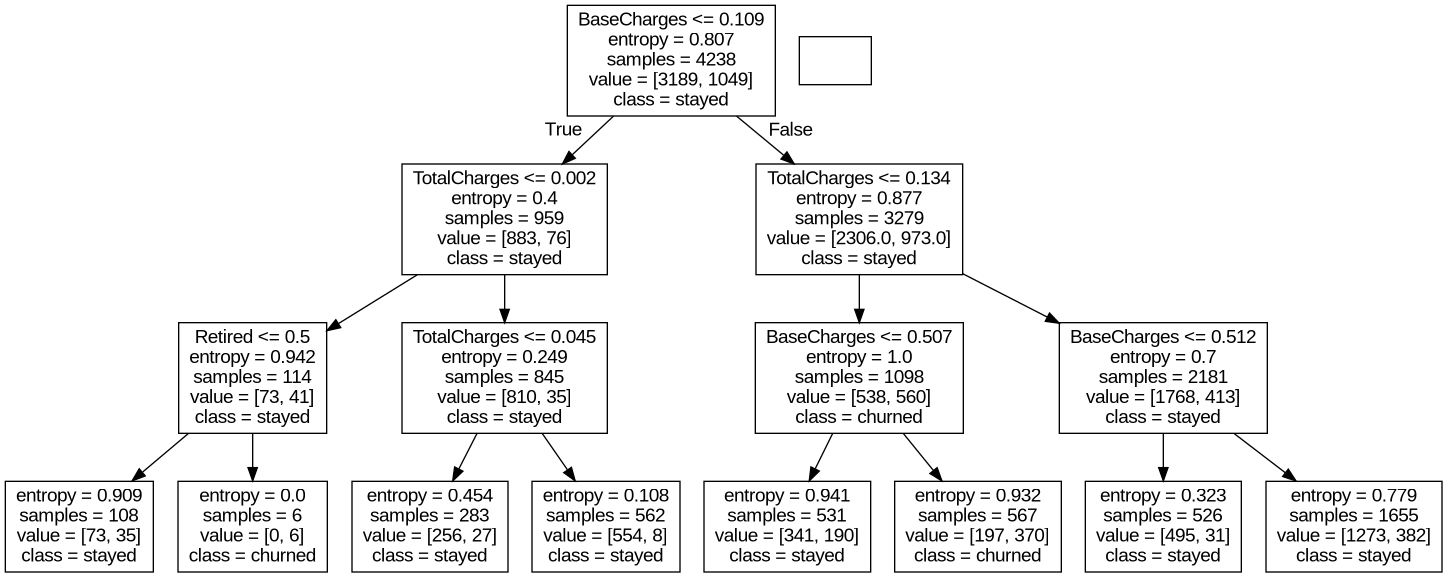

In [54]:
# Create DOT data
dot_data = tree.export_graphviz(tree_clf1,
                                feature_names=df_num_processed.columns.values.tolist(),
                                class_names=cls_names,
                               )

# Draw graph
graph = pydotplus.graph_from_dot_data(dot_data)

# Show graph
Image(graph.create_png())

In [55]:
# accuracy of the model on the training set
tree_clf1.score(df_num_processed, y)

0.7947144879660217

### Model 2: Decision tree with ordinal encoding

Next, I include the categorical variables. I use a pipeline so the preprocessing steps are fitted once on the training set and reused for the test set.

In [56]:
# get categorical attributes
df_cat = X.select_dtypes(['object'])
df_cat.describe()

,ElectronicBilling,ContractType,PaymentMethod,Education,Gender,DeviceProtection,HasPhoneService,InternetServiceCategory,MultipleLines,OnlineBackup,OnlineSecurity,StreamingMovies,StreamingTelevision,TechnicalSupport
count,4238,4235,4238,4229,4236,4238,4238,4238,4238,4238,4238,4238,4238,4238
unique,2,3,4,5,2,3,2,3,3,3,3,3,3,3
top,Yes,Month-to-month,Electronic check,Highschool or below,Male,No,1,Fiber optic,No,No,No,Yes,No,No
freq,2521,2235,1270,1145,2131,1822,3818,1853,1970,1840,2070,1672,1667,2050


In [57]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

# Define the numerical and categorical columns once
num_cols = ['BaseCharges', 'TotalCharges', 'Retired', 'HasPartner', 'HasDependents']
cat_cols = ['ElectronicBilling', 'ContractType', 'PaymentMethod', 'Education', 'Gender',
            'DeviceProtection', 'HasPhoneService', 'InternetServiceCategory', 'MultipleLines',
            'OnlineBackup', 'OnlineSecurity', 'StreamingMovies', 'StreamingTelevision', 'TechnicalSupport']

# Numerical columns: fill missing values, then scale
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])

# Categorical columns: fill missing values, then use ordinal encoding
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))  # encode unseen test categories as -1
])

preprocess = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

tree_pipeline_ordinal = Pipeline([
    ('preprocess', preprocess),
    ('model', DecisionTreeClassifier(criterion='entropy', max_depth=3))
])

In [58]:
# Fit the full pipeline once on the training set
tree_pipeline_ordinal.fit(X, y)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   MinMaxScaler())]),
                                                  ['BaseCharges',
                                                   'TotalCharges', 'Retired',
                                                   'HasPartner',
                                                   'HasDependents']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OrdinalEncoder(handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1))]),
                                                  ['ElectronicBilling',
                                                   'ContractType',
                                                   'PaymentMethod', 'Education',
                                                   'Gender', 'DeviceProtection',
                                                   'HasPhoneService',
                                                   'InternetServiceCategory',
                                                   'MultipleLines',
                                                   'OnlineBackup',
                                                   'OnlineSecurity',
                                                   'StreamingMovies',
                                                   'StreamingTelevision',
                                                   'TechnicalSupport'])])),
                ('model',
                 DecisionTreeClassifier(criterion='entropy', max_depth=3))])

In [59]:
# accuracy of the model on the training set
tree_pipeline_ordinal.score(X, y)

0.7961302501179802

### Model 3: Decision tree with one-hot encoding

Is the ordinal encoder appropriate for these variables? Most of them (e.g., PaymentMethod, InternetServiceCategory) have no natural order, so one-hot encoding is more appropriate. I modify the pipeline to use the one-hot encoder.

In [60]:
from sklearn.preprocessing import OneHotEncoder

# Categorical columns: fill missing values, then use one-hot encoding
cat_pipeline_onehot = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))  # ignore unseen test categories
])

preprocess_onehot = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline_onehot, cat_cols)
])

In [61]:
# With one-hot encoding, a tree with max_depth=3 can only use a few of the columns.
# What if we do not limit the depth of the tree?
tree_pipeline_full = Pipeline([
    ('preprocess', preprocess_onehot),
    ('model', DecisionTreeClassifier(criterion='entropy'))
])
tree_pipeline_full.fit(X, y)
tree_pipeline_full.score(X, y)

0.9988201982067013

The tree without a depth limit is almost perfect on the training set. This is a huge tree that memorizes the training data, which leads to the *overfitting* problem, so I do not use it. I set max_depth=5 to keep the tree simple but allow it to use more variables than Model 2.

In [62]:
tree_pipeline_onehot = Pipeline([
    ('preprocess', preprocess_onehot),
    ('model', DecisionTreeClassifier(criterion='entropy', max_depth=5))
])
tree_pipeline_onehot.fit(X, y)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   MinMaxScaler())]),
                                                  ['BaseCharges',
                                                   'TotalCharges', 'Retired',
                                                   'HasPartner',
                                                   'HasDependents']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['ElectronicBilling',
                                                   'ContractType',
                                                   'PaymentMethod', 'Education',
                                                   'Gender', 'DeviceProtection',
                                                   'HasPhoneService',
                                                   'InternetServiceCategory',
                                                   'MultipleLines',
                                                   'OnlineBackup',
                                                   'OnlineSecurity',
                                                   'StreamingMovies',
                                                   'StreamingTelevision',
                                                   'TechnicalSupport'])])),
                ('model',
                 DecisionTreeClassifier(criterion='entropy', max_depth=5))])

In [63]:
# accuracy of the model on the training set
tree_pipeline_onehot.score(X, y)

0.817602642756017

All three models are more accurate on the training set than the naive all-zero model (75.2%). The accuracy on the training set is not the real test. The Kaggle score on the test set will tell how good the models are.

## 6. Making Predictions for Submission on Kaggle

When we make predictions, the input dataframe we feed into the model **MUST** match the structure of the training dataframe.

In [64]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1060 entries, 0 to 1059
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   BaseCharges              1060 non-null   float64
 1   TotalCharges             1058 non-null   float64
 2   ElectronicBilling        1060 non-null   object 
 3   ContractType             1058 non-null   object 
 4   PaymentMethod            1060 non-null   object 
 5   Retired                  1060 non-null   int64  
 6   HasPartner               1060 non-null   int64  
 7   HasDependents            1060 non-null   int64  
 8   Education                1059 non-null   object 
 9   Gender                   1058 non-null   object 
 10  DeviceProtection         1060 non-null   object 
 11  HasPhoneService          1060 non-null   object 
 12  InternetServiceCategory  1060 non-null   object 
 13  MultipleLines            1060 non-null   object 
 14  OnlineBackup            

### Model 1

In [65]:
# select only numerical attributes
df_test_num = df_test.select_dtypes(include=['int64','float64'])
df_test_num.isnull().sum()

,0
BaseCharges,0
TotalCharges,2
Retired,0
HasPartner,0
HasDependents,0


In [66]:
# fill the missing values using the imputer we created for the training set
df_test_num_fill_median = median_imputer.transform(df_test_num)

# convert df_test_num_fill_median to dataframe
df_test_num_fill_median = pd.DataFrame(df_test_num_fill_median, columns=df_test_num.columns)
df_test_num_fill_median.isnull().sum()  # no missing values

,0
BaseCharges,0
TotalCharges,0
Retired,0
HasPartner,0
HasDependents,0


In [67]:
# Since the training set is scaled, we must use the same scaler for the test set too.
# Use .transform(), not .fit_transform()
df_test_num_fill_median_scaled = min_max_scaler.transform(df_test_num_fill_median)

# change df_test_num_fill_median_scaled into dataframe
df_test_num_processed = pd.DataFrame(df_test_num_fill_median_scaled, columns=df_test_num_fill_median.columns)
df_test_num_processed.head()

,BaseCharges,TotalCharges,Retired,HasPartner,HasDependents
0,0.613930,0.118396,0.0,1.0,1.0
1,0.464677,0.523788,0.0,1.0,0.0
2,0.612935,0.550898,0.0,1.0,1.0
3,0.584080,0.522915,0.0,0.0,0.0
4,0.663184,0.698721,0.0,0.0,1.0


In [68]:
# the column array for the testing input dataframe
df_test_num_processed.columns.values

array(['BaseCharges', 'TotalCharges', 'Retired', 'HasPartner',
       'HasDependents'], dtype=object)

In [69]:
# the column array for the training input dataframe
df_num_processed.columns.values

array(['BaseCharges', 'TotalCharges', 'Retired', 'HasPartner',
       'HasDependents'], dtype=object)

In [70]:
# make prediction using the first tree and convert to integer
y_hat1 = tree_clf1.predict(df_test_num_processed).astype(int)
y_hat1.shape

(1060,)

In [71]:
# make the dataframe for submission by combining two columns
tree_num_submit = pd.DataFrame({
    'CustomerNo': df_test_id,
    'Churn': y_hat1,
})
tree_num_submit.head()

,CustomerNo,Churn
0,1203,1
1,1204,0
2,1208,0
3,1220,0
4,1221,0


In [72]:
# save the resulting dataframe as a csv file for Kaggle submission
tree_num_submit.to_csv(f'{output_dir}/churn_tree_num_submit.csv', index=False)

### Model 2

In [73]:
# Predict directly from the test dataframe
# The pipeline applies the same imputer, scaler, and ordinal encoder learned from training data
y_hat2 = tree_pipeline_ordinal.predict(df_test).astype(int)
y_hat2.shape

(1060,)

In [74]:
tree_ordinal_submit = pd.DataFrame({
    'CustomerNo': df_test_id,
    'Churn': y_hat2,
})
tree_ordinal_submit.head()

,CustomerNo,Churn
0,1203,1
1,1204,0
2,1208,0
3,1220,0
4,1221,0


In [75]:
tree_ordinal_submit.to_csv(f'{output_dir}/churn_tree_ordinal_submit.csv', index=False)

### Model 3

In [76]:
y_hat3 = tree_pipeline_onehot.predict(df_test).astype(int)
y_hat3.shape

(1060,)

In [77]:
tree_onehot_submit = pd.DataFrame({
    'CustomerNo': df_test_id,
    'Churn': y_hat3,
})
tree_onehot_submit.head()

,CustomerNo,Churn
0,1203,1
1,1204,0
2,1208,0
3,1220,0
4,1221,0


In [78]:
tree_onehot_submit.to_csv(f'{output_dir}/churn_tree_onehot_submit.csv', index=False)

Submit these three files to Kaggle. Check the scores and ranking.